# Example 1: a halo catalog from tiled initial conditions

This notebook runs a complete (if small) pipeline on one GPU:

1. **ictile** generates the linear (Zel'dovich) displacement field of a periodic box, one tile at a time.
2. The **N-body emulator** of [Jamieson et al. (2024)](https://arxiv.org/abs/2408.07699)
   ([jax_nbody_emulator](https://github.com/dsjamieson/jax_nbody_emulator)) turns the linear
   displacement into the nonlinear displacement at redshift $z$, as an N-body simulation would.
   Particle $i$ starts at lattice point $q_i$ and ends at $x_i = q_i + \psi(q_i)$.
3. **jztree** ([jz-tree](https://github.com/jstuecker/jztree)) finds friends-of-friends (FoF) halos.

The output is a halo catalog (masses and positions), saved to a file, and its mass function.

The box is processed in independent tiles, so the same code works for boxes much larger than GPU memory;
only the run time grows. See `README.md` in this directory for installation.

**Note on linking length:** FoF halo catalogs from N-body simulations conventionally use a linking length $b = 0.2$
(in units of the mean interparticle spacing). The emulator's halos are slightly more diffuse than N-body halos, so at
$b = 0.2$ their FoF masses come out ~6–7% higher, at the same abundance, than in the Quijote N-body simulations
(which have the same resolution). We found that $b = 0.18$ reproduces Quijote's FoF($b = 0.2$) masses to ~1.5% from
$2.5 \times 10^{13}$ to $2 \times 10^{15}\,M_\odot/h$. So this notebook uses `LINKING_LENGTH = 0.18`, and its halos
stand in for FoF($b = 0.2$) halos in an N-body simulation. This was calibrated only at $z = 0$ in the Quijote fiducial
cosmology; the best value may differ at other redshifts or in other cosmologies. The mass function at the end compares
the two.

## Global parameters

Change these and re-run the notebook. With the defaults, the whole notebook takes ~8 minutes on an NVIDIA L40S GPU.

In [1]:
NSIDE = 1024            # particles per side. The box is NSIDE * 1000/512 Mpc/h (the emulator's fixed resolution).
SEED = 1                # random seed of the initial conditions
REDSHIFT = 0.0          # output redshift (the emulator was trained for 0 <= z <= 3)

TILE = 128              # each tile produces the halos of a TILE^3 region. Must be a multiple of 8 and divide NSIDE.
                        # GPU memory: TILE = 128 needs ~20 GB to run but ~35 GB while compiling;
                        # TILE = 64 needs ~9 GB / ~15 GB but is ~3x slower. Keep TILE <= 176 (see notes at the end).

# NOTE: 0.18, not the usual 0.2, so that the halos match N-body FoF(b = 0.2) halos. See "Note on linking length" above.
LINKING_LENGTH = 0.18   # FoF linking length, in units of the mean interparticle spacing
NMIN = 20               # minimum number of particles per halo

# Cosmology: flat LCDM, Quijote fiducial. The emulator was trained for 0.1 <= Omega_m <= 0.5.
OMEGA_M, OMEGA_B, H0, N_S, SIGMA_8 = 0.3175, 0.049, 67.11, 0.9624, 0.834

OUTFILE = 'halos.npz'   # output halo catalog

## Imports

In [2]:
import os
# JAX preallocates 75% of GPU memory by default. Compiling the emulator temporarily needs ~1.7x the memory
# it needs to run (XLA times several convolution algorithms), so let JAX use more. Must be set before importing jax.
os.environ.setdefault('XLA_PYTHON_CLIENT_MEM_FRACTION', '0.9')

import contextlib, io, itertools, time
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import camb
import ictile
import jax_nbody_emulator as jne
import jztree as jz

print('jax', jax.__version__, '| GPU:', jax.devices()[0].device_kind)

jax 0.12.0.1 | GPU: NVIDIA L40S


## Linear power spectrum (CAMB)

ictile needs the linear matter power spectrum $P(k)$ at $z=0$, as a function of $k$ in $h$/Mpc (the inverse of
the units of the box size, Mpc/$h$). It is normalized to $\sigma_8$.

In [3]:
h = H0 / 100
pars = camb.set_params(H0=H0, ombh2=OMEGA_B * h**2, omch2=(OMEGA_M - OMEGA_B) * h**2, mnu=0, ns=N_S, As=2e-9)
pars.set_matter_power(redshifts=[0.0], kmax=20.0)
pars.NonLinear = camb.model.NonLinear_none
results = camb.get_results(pars)
k_tab, _, pk_tab = results.get_matter_power_spectrum(minkh=1e-4, maxkh=20, npoints=1000)
pk_tab = pk_tab[0] * (SIGMA_8 / results.get_sigma8_0())**2

def pk_lin(k):
    # P(k) [(Mpc/h)^3] at z=0; log-log interpolation, power-law extrapolation, P(0) = 0.
    k = np.asarray(k, dtype=np.float64)
    lk = np.log(np.maximum(k, 1e-30))
    lk0, lp0 = np.log(k_tab), np.log(pk_tab)
    lp = np.interp(lk, lk0, lp0)
    lp = np.where(lk < lk0[0], lp0[0] + (lk - lk0[0]) * (lp0[1] - lp0[0]) / (lk0[1] - lk0[0]), lp)
    lp = np.where(lk > lk0[-1], lp0[-1] + (lk - lk0[-1]) * (lp0[-1] - lp0[-2]) / (lk0[-1] - lk0[-2]), lp)
    return np.where(k > 0, np.exp(lp), 0.0)

## Box, particles and tiles

The emulator only works at its training resolution: the particles start on a cubic lattice with spacing
$1000/512$ Mpc/$h$. So `NSIDE` sets both the number of particles and the box size, and the particle mass is fixed.

Each tile has three nested regions:

```
   |<- 48 ->|<- 24 ->|<----- TILE ----->|<- 24 ->|<- 48 ->|
   |<----------- IC tile = emulator input ---------------->|      TILE + 144 cells per side
            |<------ emulator output = FoF region ->|              TILE +  48
                     |<-- halos kept -->|                          TILE
```

- The emulator's output depends on its input within exactly 48 cells, so it needs 48 cells of padding on each side.
- FoF needs padding too, so that halos near the edge of the tile are complete: 24 cells per side was enough
  to reproduce an untiled catalog exactly, for $b \le 0.35$ in a $(4\,{\rm Gpc}/h)^3$ box at $z=0$.
- A halo can be found by several tiles. It is kept by the tile whose central `TILE`$^3$ region contains the
  midpoint of the halo's *Lagrangian* bounding box (the box enclosing its particles' lattice points $q_i$).
  Every tile that finds the halo finds the same set of particles, so exactly one tile keeps it.

In [4]:
GRID = 1000 / 512                         # particle spacing [Mpc/h], fixed by the emulator's training
BOX = NSIDE * GRID                        # box size [Mpc/h]
RHO_CRIT = 2.77536627e11                  # critical density [h^2 Msun / Mpc^3]
M_PART = OMEGA_M * RHO_CRIT * GRID**3     # particle mass [Msun/h]

EMU_PAD = 48                  # emulator padding [cells per side]
FOF_PAD = 24                  # FoF padding [cells per side]
NFOF = TILE + 2 * FOF_PAD     # side of the FoF region (= emulator output)
NIN = NFOF + 2 * EMU_PAD      # side of the IC tile (= emulator input)
NTILES = NSIDE // TILE        # tiles per side

assert NSIDE % TILE == 0, 'TILE must divide NSIDE'
assert TILE % 8 == 0, 'the emulator needs output sizes that are multiples of 8'
assert NIN <= NSIDE // 2, f'ictile tiles can be at most NSIDE/2 = {NSIDE // 2} cells: use a smaller TILE'

print(f'box: {BOX:.0f} Mpc/h, {NSIDE}^3 = {NSIDE**3:.3g} particles of {M_PART:.3g} Msun/h')
print(f'{NTILES}^3 = {NTILES**3} tiles; per tile: IC tile {NIN}^3, FoF region {NFOF}^3, halos kept from {TILE}^3')

box: 2000 Mpc/h, 1024^3 = 1.07e+09 particles of 6.57e+11 Msun/h
8^3 = 512 tiles; per tile: IC tile 272^3, FoF region 176^3, halos kept from 128^3


## Step 1: initial conditions (ictile)

`TiledGRF.displacement_tile(start)` returns the linear displacement $\psi(q)$ at $z=0$, in the units of `box_size`
(Mpc/$h$), on a tile of shape `ntile` whose lower corner is at lattice point `start`. Its shape is
`(3, NIN, NIN, NIN)`, where `psi[c, i, j, k]` is the displacement along axis $c$ of the particle at $q = (i,j,k)$:
the convention the emulator expects. The box is periodic, and every tile is part of the same realization.

In [5]:
grf = ictile.TiledGRF(nside=NSIDE, box_size=BOX, pk=pk_lin, seed=SEED, ntile=NIN)

def initial_conditions(i, j, k):
    # Linear displacement [Mpc/h] on the IC tile of tile (i, j, k), shape (3, NIN, NIN, NIN).
    start = np.array([i, j, k]) * TILE - (EMU_PAD + FOF_PAD)
    return grf.displacement_tile(start % NSIDE)      # the box is periodic

## Step 2: N-body emulator

The emulator is a 3D U-Net. Its input is the linear displacement at $z=0$ in Mpc/$h$ (it multiplies by the growth
factor $D(z)$ itself), and it returns the nonlinear displacement at `REDSHIFT`, 48 cells smaller on each side.
$\Omega_m$ and $z$ are inputs to the network; the other cosmological parameters enter only through $P(k)$.

`premodulate=True` folds $\Omega_m$ and $z$ into the network weights once, which makes each call faster.
The parameters are passed to the jitted function as an argument, rather than captured, so that they are not baked
into the compiled program as constants. On recent NVIDIA GPUs, JAX runs the convolutions in TF32 by default.

In [6]:
with contextlib.redirect_stdout(io.StringIO()):     # modulating the parameters prints a lot
    emulator = jne.create_emulator(premodulate=True, premodulate_z=REDSHIFT, premodulate_Om=OMEGA_M, compute_vel=False)

@jax.jit
def emulate(params, psi_lin):
    # Linear z=0 displacement, shape (3, n+96, n+96, n+96) -> nonlinear displacement at REDSHIFT, shape (3, n, n, n).
    Dz = jne.growth_factor(jnp.array([REDSHIFT]), jnp.array([OMEGA_M]))
    return emulator.model.apply(params, psi_lin[None], Dz)[0]

## Step 3: friends-of-friends halos (jztree)

`jz.fof.fof_labels()` links particles closer than `rlink`, and returns for each particle the index of a
representative particle of its group. From these labels, `jax.ops.segment_*` reductions give each group's
particle count, Lagrangian bounding box (for deciding which tile keeps it) and center of mass.

The FoF region is not periodic, so positions are in tile coordinates. Everything has static shapes so that it
can be jitted: the halo arrays have a fixed length `MAX_HALOS`, of which the first `nhalos` entries are used.

In [7]:
MAX_HALOS = NFOF**3 // 100      # tiles have ~0.003 halos per particle, so this leaves a margin

@jax.jit
def find_halos(psi_nl):
    # psi_nl: nonlinear displacement (3, NFOF, NFOF, NFOF) [Mpc/h] on the FoF region of one tile.
    # Returns (nhalos, keep, npart, com): keep[h] is True if this tile keeps halo h; com is its center of mass
    # [Mpc/h], relative to the corner of the FoF region.
    q = jnp.stack(jnp.meshgrid(*[jnp.arange(NFOF, dtype=jnp.int32)] * 3, indexing='ij'), axis=-1).reshape(-1, 3)
    x = q * GRID + psi_nl.reshape(3, -1).T                       # particle positions [Mpc/h], shape (P, 3)
    P = x.shape[0]
    _, label = jz.fof.fof_labels(x, rlink=LINKING_LENGTH * GRID, output_order='input')

    npart = jax.ops.segment_sum(jnp.ones(P, jnp.int32), label, num_segments=P)
    is_halo = npart >= NMIN
    nhalos = jnp.sum(is_halo)
    rep = jnp.nonzero(is_halo, size=MAX_HALOS, fill_value=0)[0]   # one representative particle per halo

    qmin = jax.ops.segment_min(q, label, num_segments=P)[rep]    # Lagrangian bounding box
    qmax = jax.ops.segment_max(q, label, num_segments=P)[rep]
    mid = (qmin + qmax) // 2
    keep = jnp.all((mid >= FOF_PAD) & (mid < FOF_PAD + TILE), axis=1) & (jnp.arange(MAX_HALOS) < nhalos)

    dx = jax.ops.segment_sum(x - x[label], label, num_segments=P)[rep]   # offsets from the representative,
    com = x[rep] + dx / npart[rep, None]                                 # for float32 precision
    return nhalos, keep, npart[rep], com

## One tile

Run the first tile twice: the first call compiles the emulator and the halo finder (this takes a while, and
most of the GPU memory), and the second shows the speed.

In [8]:
def run_tile(i, j, k):
    psi_lin = initial_conditions(i, j, k)
    psi_nl = emulate(emulator.params, psi_lin)
    return psi_nl, jax.device_get(find_halos(psi_nl))

t0 = time.time()
run_tile(0, 0, 0)
print(f'first tile, including compilation: {time.time() - t0:.0f} s')

t0 = time.time()
psi_nl, (nhalos, keep, npart, com) = run_tile(0, 0, 0)
dt = time.time() - t0
print(f'one tile: {dt:.2f} s, so all {NTILES**3} tiles will take ~{dt * NTILES**3 / 60:.0f} min')
print(f'tile (0,0,0): {nhalos} halos with >= {NMIN} particles, of which this tile keeps {keep.sum()}')

first tile, including compilation: 58 s


one tile: 0.73 s, so all 512 tiles will take ~6 min
tile (0,0,0): 16364 halos with >= 20 particles, of which this tile keeps 6310


A 30 Mpc/$h$ slice through the FoF region of this tile: the projected particle density, the halos the tile keeps
(white circles, area proportional to mass) and the halos it leaves to its neighbors (grey). The dashed square is
the central `TILE`$^3$ region.

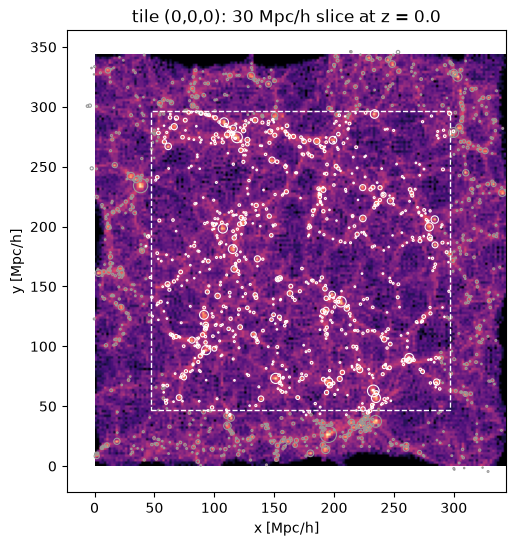

In [9]:
x = (np.indices((NFOF,) * 3).reshape(3, -1) * GRID + np.asarray(psi_nl).reshape(3, -1))   # positions [Mpc/h]
zc, dz = NFOF * GRID / 2, 15.0
sl = np.abs(x[2] - zc) < dz
ext = NFOF * GRID
img, _, _ = np.histogram2d(x[0, sl], x[1, sl], bins=NFOF, range=[[0, ext], [0, ext]])   # one bin per lattice cell (no aliasing)

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(np.log10(1 + img.T), origin='lower', extent=[0, ext, 0, ext], cmap='magma')
h = (np.arange(len(keep)) < nhalos) & (np.abs(com[:, 2] - zc) < dz)
for kept, color in [(False, '0.6'), (True, 'white')]:
    m = h & (keep == kept)
    ax.scatter(com[m, 0], com[m, 1], s=npart[m] / 20, facecolors='none', edgecolors=color, linewidths=0.8)
a, b = FOF_PAD * GRID, (FOF_PAD + TILE) * GRID
ax.plot([a, b, b, a, a], [a, a, b, b, a], '--', color='white', lw=1)
ax.set_xlabel('x [Mpc/h]'); ax.set_ylabel('y [Mpc/h]')
ax.set_title(f'tile (0,0,0): {2 * dz:.0f} Mpc/h slice at z = {REDSHIFT}')
plt.show()

## All tiles

The loop over tiles is the whole pipeline. For each tile, the halos it keeps are shifted to box coordinates and
appended to the catalog.

In [10]:
pos, npart_all = [], []
tiles = list(itertools.product(range(NTILES), repeat=3))
t0 = time.time()
for it, (i, j, k) in enumerate(tiles):
    _, (nhalos, keep, npart, com) = run_tile(i, j, k)
    assert nhalos <= MAX_HALOS, 'too many halos in a tile: increase MAX_HALOS'
    origin = (np.array([i, j, k]) * TILE - FOF_PAD) * GRID      # corner of the FoF region [Mpc/h]
    pos.append((com[keep] + origin) % BOX)
    npart_all.append(npart[keep])
    if (it + 1) % max(1, len(tiles) // 8) == 0:
        el = time.time() - t0
        print(f'{it + 1}/{len(tiles)} tiles: {el / 60:.1f} min elapsed, ~{el / (it + 1) * (len(tiles) - it - 1) / 60:.1f} min to go')

npart_all = np.concatenate(npart_all)
order = np.argsort(-npart_all)                   # most massive first
npart_all = npart_all[order]
pos = np.concatenate(pos)[order]
mass = npart_all * M_PART

np.savez(OUTFILE, mass=mass, pos=pos, npart=npart_all, particle_mass=M_PART, box_size=BOX, nside=NSIDE,
         seed=SEED, redshift=REDSHIFT, linking_length=LINKING_LENGTH)
print(f'{len(mass)} halos with >= {NMIN} particles ({NMIN * M_PART:.2g} Msun/h); most massive: {mass[0]:.3g} Msun/h')
print(f'saved {OUTFILE}: mass [Msun/h], pos [Mpc/h], npart')

64/512 tiles: 0.8 min elapsed, ~5.5 min to go


128/512 tiles: 1.6 min elapsed, ~4.7 min to go


192/512 tiles: 2.4 min elapsed, ~3.9 min to go


256/512 tiles: 3.2 min elapsed, ~3.2 min to go


320/512 tiles: 4.0 min elapsed, ~2.4 min to go


384/512 tiles: 4.8 min elapsed, ~1.6 min to go


448/512 tiles: 5.6 min elapsed, ~0.8 min to go


512/512 tiles: 6.4 min elapsed, ~0.0 min to go


3148109 halos with >= 20 particles (1.3e+13 Msun/h); most massive: 5.17e+15 Msun/h
saved halos.npz: mass [Msun/h], pos [Mpc/h], npart


## Mass function

The halo mass function $dn/d\ln M$, compared with the [Quijote](https://quijote-simulations.readthedocs.io) N-body
simulations (Villaescusa-Navarro et al. 2020): FoF ($b = 0.2$) halos at $z = 0$ in 64 realizations of the same
cosmology at the same resolution. Quijote is also the simulation suite the emulator was trained on. Masses are
$M = N_{\rm part}\, m_{\rm part}$ for both. Quijote's halo counts are included in `quijote_hmf/` (with the script that
made them), so nothing needs to be downloaded.

If you change the redshift or the cosmology, the comparison is with the fit of
[Crocce et al. (2010)](https://arxiv.org/abs/0907.0019) to FoF ($b = 0.2$) halos instead, using that fit's mass
definition (FoF masses corrected for discreteness, following Warren et al. 2006). The fit was calibrated on halos with at
least 50–200 particles, so it says little below ~50 particles ($3 \times 10^{13}\,M_\odot/h$).

The emulator's halos use `LINKING_LENGTH` (0.18 by default), and Quijote's use $b = 0.2$: see the note on linking
length at the top. With the defaults, the two agree to within ~3% from $4 \times 10^{13}$ to $10^{15}\,M_\odot/h$, and
the emulator has ~5% fewer of the smallest halos (20–40 particles). With $b = 0.2$, it would have ~10–20% more halos
than Quijote above $10^{14}\,M_\odot/h$.

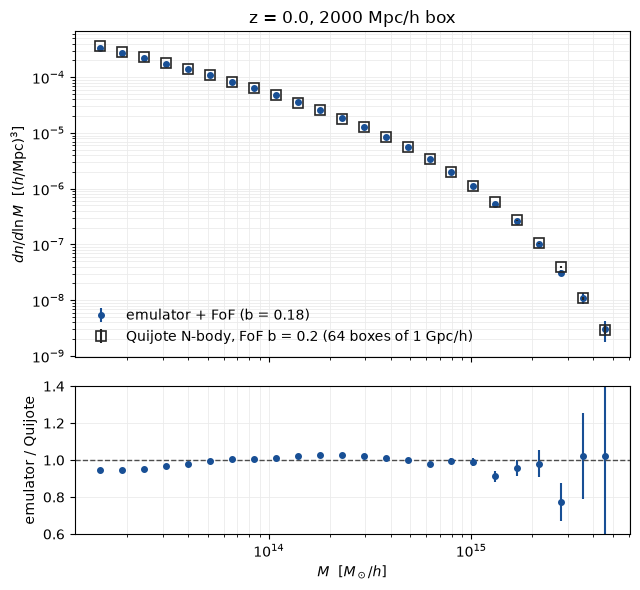

In [11]:
def sigma_m(M):
    # rms linear density contrast at z=0 in top-hat spheres of mass M [Msun/h]
    R = (3 * M / (4 * np.pi * OMEGA_M * RHO_CRIT))**(1 / 3)
    lk = np.linspace(np.log(1e-4), np.log(20.0), 4000)
    kR = np.exp(lk)[None, :] * R[:, None]
    W = 3 * (np.sin(kR) - kR * np.cos(kR)) / kR**3
    return np.sqrt(np.trapezoid(np.exp(3 * lk) * pk_lin(np.exp(lk)) * W**2, lk, axis=1) / (2 * np.pi**2))

def dndlnm_crocce(M, z):
    # Crocce et al. (2010), FoF b=0.2: f(sigma) = A (sigma^-a + b) exp(-c / sigma^2), with z-dependent parameters
    Dz = float(jne.growth_factor(jnp.array([z]), jnp.array([OMEGA_M]))[0])
    A, a, b, c = 0.58 * (1 + z)**-0.13, 1.37 * (1 + z)**-0.15, 0.3 * (1 + z)**-0.084, 1.036 * (1 + z)**-0.024
    s = sigma_m(M) * Dz
    dlns_dlnm = (np.log(sigma_m(M * 1.02)) - np.log(sigma_m(M / 1.02))) / (2 * np.log(1.02))
    f = A * (s**-a + b) * np.exp(-c / s**2)
    return OMEGA_M * RHO_CRIT / M * f * np.abs(dlns_dlnm)

# Bins in particle number, with edges at half-integers (so each bin holds a whole number of integer N values)
edges_n = np.unique(np.round(np.geomspace(NMIN, npart_all.max() + 1, 25))) - 0.5
n_mid = np.sqrt(edges_n[1:] * edges_n[:-1])

def binned_hmf(npart, nhalos, volume, mass_of_n):
    # dn/dlnM [(h/Mpc)^3] and its Poisson error in the bins edges_n, from halo particle counts (and multiplicities)
    counts, _ = np.histogram(npart, edges_n, weights=nhalos)
    dlnm = np.diff(np.log(mass_of_n(edges_n)))
    return counts / volume / dlnm, np.sqrt(counts) / volume / dlnm

QUIJOTE = 'quijote_hmf/quijote_fof_z0.txt'
QUIJOTE_COSMOLOGY = (0.3175, 0.049, 67.11, 0.9624, 0.834)

if (REDSHIFT == 0) and ((OMEGA_M, OMEGA_B, H0, N_S, SIGMA_8) == QUIJOTE_COSMOLOGY):
    # Quijote: same cosmology and resolution, FoF b = 0.2, z = 0
    mass_of_n = lambda n: n * M_PART
    meta = {}
    for line in open(QUIJOTE):
        for key in ('nreal', 'box_size'):
            if line.startswith(f'# {key} = '):
                meta[key] = float(line.split('=')[1])
    q_npart, q_nhalos = np.loadtxt(QUIJOTE, dtype=np.int64, unpack=True)
    ref, ref_err = binned_hmf(q_npart, q_nhalos, meta['nreal'] * meta['box_size']**3, mass_of_n)
    ref_name, ref_label = 'Quijote', f"Quijote N-body, FoF b = 0.2 ({meta['nreal']:.0f} boxes of 1 Gpc/h)"
else:
    # The Crocce et al. fit uses FoF masses with the Warren et al. (2006) correction, M = N m_part (1 - N^-0.6)
    mass_of_n = lambda n: n * (1 - n**-0.6) * M_PART
    ref, ref_err = dndlnm_crocce(mass_of_n(n_mid), REDSHIFT), None
    ref_name, ref_label = 'fit', 'Crocce et al. (2010) fit, FoF b = 0.2'

m = mass_of_n(n_mid)
hmf, err = binned_hmf(npart_all, np.ones(len(npart_all)), BOX**3, mass_of_n)
ok = (hmf > 0) & (ref > 0)
ratio = hmf[ok] / ref[ok]
ratio_err = ratio * np.hypot(err[ok] / hmf[ok], 0 if ref_err is None else ref_err[ok] / ref[ok])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6.5, 6), sharex=True, gridspec_kw=dict(height_ratios=[2.2, 1]))
e = hmf > 0
ax1.errorbar(m[e], hmf[e], err[e], fmt='o', ms=4, color='#184f95', label=f'emulator + FoF (b = {LINKING_LENGTH})')
if ref_err is None:
    ax1.plot(m, ref, '--', color='0.3', label=ref_label)
else:
    q = ref > 0
    ax1.errorbar(m[q], ref[q], ref_err[q], fmt='s', ms=7, mfc='none', mew=1.2, color='0.15', label=ref_label, zorder=3)
ax1.set(xscale='log', yscale='log', ylabel=r'$dn/d\ln M$  [$(h/{\rm Mpc})^3$]', title=f'z = {REDSHIFT}, {BOX:.0f} Mpc/h box')
ax1.legend(frameon=False)
ax2.errorbar(m[ok], ratio, ratio_err, fmt='o', ms=4, color='#184f95')
ax2.axhline(1, color='0.3', ls='--', lw=1)
ax2.set(xscale='log', ylim=(0.6, 1.4), xlabel=r'$M$  [$M_\odot/h$]', ylabel=f'emulator / {ref_name}')
for ax in (ax1, ax2):
    ax.grid(True, which='both', color='0.92', lw=0.6)
plt.tight_layout()
plt.show()

## Reading the catalog

`halos.npz` holds `mass` [$M_\odot/h$], `pos` [Mpc/$h$, in $[0, $ `box_size` $)$], `npart`, and the run's parameters.

In [12]:
cat = np.load(OUTFILE)
print({key: cat[key].shape for key in cat.files})
print('five most massive halos [Msun/h]:', cat['mass'][:5])

{'mass': (3148109,), 'pos': (3148109, 3), 'npart': (3148109,), 'particle_mass': (), 'box_size': (), 'nside': (), 'seed': (), 'redshift': (), 'linking_length': ()}
five most massive halos [Msun/h]: [5.17016871e+15 4.80645144e+15 4.63312769e+15 4.37970736e+15
 4.26547125e+15]


## Notes

- **Tile size.** Larger tiles are faster, since each tile recomputes 72 cells of padding per side, but need more GPU
  memory. Above `TILE = 176` (an emulator input of $\gtrsim 322^3$), some of the emulator's internal arrays exceed
  $2^{31}$ elements and the convolutions become 10–20× slower without any error message.
- **Compile-time memory.** XLA picks the fastest convolution algorithms by trying them on the GPU when the emulator is
  first compiled, which needs ~1.7× the memory of running it. If compilation runs out of memory, use a smaller `TILE`.
- **Velocities.** `create_emulator(compute_vel=True)` also returns particle velocities (about 2.3× the cost), which
  could be added to the catalog. `jz.fof.fof_and_catalogue()` computes richer per-halo quantities (e.g. velocities,
  inertia radii).
- **Reproducibility.** The emulator runs in TF32 by default on recent GPUs, and XLA picks convolution algorithms by
  timing them, so the displacements differ slightly (~$10^{-4}$ Mpc/$h$) between GPUs, software versions and even runs.
  That moves a particle or two in or out of a few percent of the halos; the mass function is unaffected.

## References

- **N-body emulator:** D. Jamieson et al. (2024),
  [Field-level emulation of cosmic structure formation with cosmology and redshift dependence](https://arxiv.org/abs/2408.07699),
  arXiv:2408.07699. Earlier versions: D. Jamieson et al. (2022),
  [Field level neural network emulator for cosmological N-body simulations](https://arxiv.org/abs/2206.04594),
  arXiv:2206.04594; D. Jamieson et al. (2022),
  [Simple lessons from complex learning: what a neural network model learns about cosmic structure formation](https://arxiv.org/abs/2206.04573),
  arXiv:2206.04573.
- **jz-tree:** J. Stücker et al. (2026),
  [JZ-Tree: GPU friendly neighbour search and friends-of-friends with dual tree walks in JAX plus CUDA](https://arxiv.org/abs/2604.05885),
  arXiv:2604.05885.
- **Quijote simulations:** F. Villaescusa-Navarro et al. (2020), [The Quijote simulations](https://arxiv.org/abs/1909.05273),
  ApJS 250, 2.
- **CAMB:** A. Lewis, A. Challinor and A. Lasenby (2000),
  [Efficient computation of CMB anisotropies in closed FRW models](https://arxiv.org/abs/astro-ph/9911177), ApJ 538, 473.
- **Mass function fit:** M. Crocce et al. (2010),
  [Simulating the Universe with MICE: the abundance of massive clusters](https://arxiv.org/abs/0907.0019), MNRAS 403, 1353.
- **FoF mass correction:** M. S. Warren et al. (2006),
  [Precision determination of the mass function of dark matter halos](https://arxiv.org/abs/astro-ph/0506395), ApJ 646, 881.